# Imports

In [60]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import os, pickle
import tmap as tm
import numpy as np
import pandas as pd
import networkx as nx
from io import StringIO
from functools import reduce
from matplotlib import pyplot as plt

from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.Chem.Descriptors import MolWt
from rdkit.DataStructs import TanimotoSimilarity
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addStereoAnnotation = False

import utils
import maximum_common_graph as mcg
from new_geass import Geass
clear_output()

# Load data

<span style="color:orange">WARNING</span>: Database must have at least ID and ISOSMILES columns

In [ ]:
# TODO: VERIFICAR TODAS LAS COLUMNAS QUE HAGAN FALTA

In [2]:
database3 = pd.read_csv('data/Database3.csv')
df_lotus = pd.read_csv('data/Database_LOTUS.csv', sep='\t')

In [3]:
# Load the UCL (Unknown Compound Library)
'''
The UCL is a library in dictionary format that is empty in the first execution, but entries will be generated and used in future executions
UCL is a dict with the following format:
{
    "UC_XXXX": rdkit mol of the compound
}
'''
try:
    if os.path.isfile('data/UCL.pkl'):
        with open('data/UCL.pkl', 'rb') as f:
            UCL = pickle.load(f)
    else:
        UCL = {}
except:
    print("Error loading the UCL, initialising as empty instead.")
    UCL = {}

# Geass with single compound

Validation step

In [35]:
# Pick the SMILES of the molecule from the database to use in the GEASS and create the mol object
# mol = Chem.MolFromSmiles(database3['ISOSMILES'].sample(24).values[0]) # Pick a specific molecule (the 24th in this case)
mol = Chem.MolFromSmiles(database3['ISOSMILES'].head()[0]) # Pick the first one

In [ ]:
geass = Geass()
final_prods = geass.get_fragments(mol)
final_Prod = reduce(Chem.CombineMols, final_prods)
geass.create_connections_graph()
geass.show_connections_graph()

# Geass with multiple compounds

<span style="color:orange">WARNING</span>: This may take a maximum of 8 seconds per molecule.

In [4]:
geass_results = {}

for index, row in database3.iterrows():
    clear_output()
    print(f'PROGRESS: [{index+1}/{len(database3)}]')
    mol = Chem.MolFromSmiles(row['ISOSMILES'])
    mol_id = row['ID']
    g = Geass()
    # Optional: add the UCL
    g.UCL = UCL
    try:
        final_prods = g.get_fragments(mol, True)
        final_Prod = reduce(Chem.CombineMols, final_prods)
        g.create_connections_graph()
        geass_results[mol_id] = g
        if g.UCL:
            UCL = g.UCL
    except:
        pass

# Update the UCL database file with the not aligned fragments
with open('data/UCL.pkl', 'wb') as f:
    pickle.dump(UCL, f)

PROGRESS: [4376/4376]


In [5]:
# You can see a fragmented compound by using the following method
geass_results['BS_0155'].show_connections_graph()

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

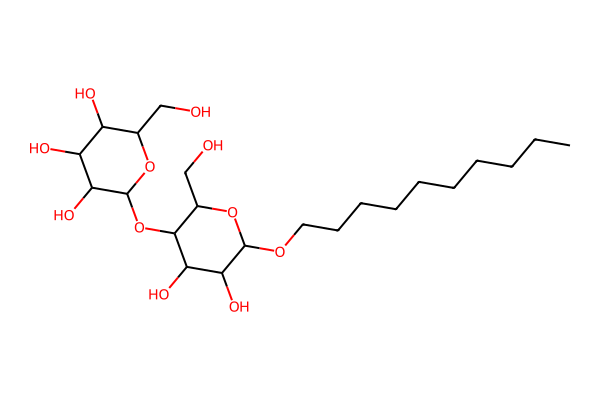

In [10]:
# And here is the same molecule before being fragmented
Chem.MolFromSmiles(database3[database3['ID'] == 'BS_0155']['ISOSMILES'].values[0])

Taking advantage of fragmentation, we will group the molecules according to whether they have the same fragments and whether they are built the same way.

# Previous steps

## Create compound edges for distance matrix

In [5]:
compound_edges = utils.create_compound_edges(geass_results)

# Create csv with all edges (nodes and reaction type)
edge_csv_string = 'ID,n1,n2,ReactionType'
for id, edges in compound_edges.items():
    for edge in edges:
        edge_csv_string = '\n'.join([edge_csv_string, f'{id},{",".join(edge)}'])

# Create the edges DataFrame
edges_df = pd.read_csv(StringIO(edge_csv_string))

with open('SECRETed_edges.csv', 'w') as csv_file:
    csv_file.write(edge_csv_string)

## Calculate fragment and compound weights for distance matrix

In [6]:
node_weight_dict = {} # Fragment weights
id_weight_dict = {} # Compound weights

for id, g in geass_results.items():
    mol_weight = MolWt(g.query_mol)
    nodes = g.G.nodes(data=True)
    for node in nodes:
        node_id = node[0]
        node_data = node[1]
        node_weight = MolWt(Chem.MolFromSmiles(node_data['SMILES']))
        node_weight_dict[f'{id}_{node_id}'] = node_weight
    id_weight_dict[id] = mol_weight

## Create UCL node similarity matrix for distance matrix

In [7]:
df_UCL = pd.DataFrame(UCL.items(), columns=['ID', 'Molecule'])

# Remove invalid molecules
df_UCL = df_UCL[df_UCL['Molecule'].notnull()].reset_index(drop=True)

# Compute Morgan fingerprints
radius = 2
nBits = 2048
morgan_fps = [GetMorganFingerprintAsBitVect(mol, radius, nBits) if mol is not None else None for mol in df_UCL['Molecule']]

# Create UCL similarity matrix
num_molecules = len(morgan_fps)
similarity_matrix = np.zeros((num_molecules, num_molecules))
for i in range(num_molecules):
    for j in range(i, num_molecules):
        if morgan_fps[i] is not None and morgan_fps[j] is not None:
            sim = TanimotoSimilarity(morgan_fps[i], morgan_fps[j])
            similarity_matrix[i, j] = sim
            similarity_matrix[j, i] = sim  # Symmetric matrix
        else:
            similarity_matrix[i, j] = 0
            similarity_matrix[j, i] = 0

# Apply similarity threshold
threshold = 0.6
similarity_matrix[similarity_matrix < threshold] = 0

# Create a DataFrame for the similarity matrix
similarity_df = pd.DataFrame(similarity_matrix, index=df_UCL['ID'], columns=df_UCL['ID'])

In [ ]:
# Save the similarity matrix to CSV (optional)
similarity_df.to_csv('sec_similarity_matrix_morgan_all.csv')

# Clustering of compounds based on their composition (Jaccard distance based matrix)

### Step 1: (Optional) Load Data from external files

<span style="color:#184cb1">NOTE</span>: If all the previous steps have been executed, the data will already be loaded for node weights (node_weights_df), compound weights (id_weights_df) and node similarity matrix (node_sim_matrix_df)

In [54]:
# 1.1 Load the edges data from SECRETed_edges_all.csv
# edges_df = pd.read_csv('SECRETed_edges.csv', sep=',', dtype={'ID': str, 'n1': str, 'n2': str, 'ReactionType': str})

In [ ]:
# 1.2 Load node weights from node_molecular_weights.csv
# node_weights_df = pd.read_csv('node_molecular_weights.csv', sep=',', dtype={'NodeID': str, 'Weight': float})

In [ ]:
# 1.3 Load ID weights from SECRETed_molecular_weights.csv
# id_weights_df = pd.read_csv('SECRETed_molecular_weights.csv', sep=',', dtype={'ID': str, 'Weight': float})

In [ ]:
# 1.4 Load node similarities from UCL_similarity_matrix_morgan.csv (square matrix format)
# node_sim_matrix_df = pd.read_csv('UCL_similarity_matrix_morgan.csv', sep=',', index_col=0)

### Step 2: Prepare Data Structures

In [ ]:
# Uncomment the last two lines of this cell if you loaded node_weights_df and id_weights_df from the previous step
# Create dictionaries for node weights and ID weights
# node_weight_dict = node_weights_df.set_index('NodeID')['Weight'].to_dict()
# id_weight_dict = id_weights_df.set_index('ID')['Weight'].to_dict()

In [8]:
# Convert node similarity matrix DataFrame to a dictionary for quick lookup
node_similarity = similarity_df.to_dict()

In [9]:
# Define the function to get node similarity
def get_node_similarity(n1, n2):
    try:
        return node_similarity[n1][n2]
    except KeyError:
        return 0.0  # Default similarity if nodes not found

### Step 3: Build Graphs per ID with Adjusted Weights

In [10]:
# Define function to get adjusted node weight
def get_adjusted_node_weight(node_id, graph_id):
    node_weight = node_weight_dict.get(node_id, 1.0)  # Default to 1.0 if not found
    id_weight = id_weight_dict.get(graph_id, 1.0)     # Default to 1.0 if not found
    adjusted_weight = node_weight / id_weight if id_weight != 0 else 0.0
    return adjusted_weight

In [11]:
# Create a dictionary to hold the edges for each graph with adjusted weights
graph_dict = {}

for idx, row in edges_df.iterrows():
    graph_id = row['ID']
    n1 = str(row['n1'])
    n2 = str(row['n2'])
    
    # Get adjusted node weights
    adjusted_node_weight_n1 = get_adjusted_node_weight(n1, graph_id)
    adjusted_node_weight_n2 = get_adjusted_node_weight(n2, graph_id)
    
    # Compute adjusted edge weight
    edge_weight = 1.0  # Base edge weight
    adjusted_edge_weight = edge_weight * adjusted_node_weight_n1 * adjusted_node_weight_n2
    
    # Initialize graph if not present
    if graph_id not in graph_dict:
        graph_dict[graph_id] = {}
    
    # Represent edge as a sorted tuple to avoid duplicates
    edge = tuple(sorted((n1, n2)))
    
    # TODO: Revisar para no sumar, sino distinguir duplicados
    # If edge already exists, sum the weights
    if edge in graph_dict[graph_id]:
        graph_dict[graph_id][edge] += adjusted_edge_weight
    else:
        graph_dict[graph_id][edge] = adjusted_edge_weight

### Step 4: Compute Adjusted Weighted Jaccard Distance Between Graphs

In [12]:
# Get a list of all graph IDs
graph_ids = list(graph_dict.keys())

# Initialize a DataFrame to hold the distances
distance_matrix = pd.DataFrame(index=graph_ids, columns=graph_ids, dtype=float)

In [13]:
# Define function to compute adjusted weighted Jaccard distance between two graphs
def adjusted_weighted_jaccard(graph_a, graph_b, threshold=0.8):
    numerator = 0.0
    denominator = 0.0

    # Build sets of edges
    edges_a = set(graph_a.keys())
    edges_b = set(graph_b.keys())
    all_edges = edges_a.union(edges_b)

    # For efficient lookup
    graph_a_weights = graph_a
    graph_b_weights = graph_b

    for edge in all_edges:
        w_a = graph_a_weights.get(edge, 0.0)
        w_b = graph_b_weights.get(edge, 0.0)
        # Edge similarity
        if edge in edges_a and edge in edges_b:
            S_e = 1.0  # Edge exists in both graphs with identical nodes
        else:
            # Check for similar edges based on node similarities
            n1_a, n2_a = edge
            similar_edges_in_b = []
            for edge_b in edges_b:
                n1_b, n2_b = edge_b
                # Compute node similarities
                S_n1 = get_node_similarity(n1_a, n1_b)
                S_n2 = get_node_similarity(n2_a, n2_b)
                S_e_candidate = (S_n1 + S_n2) / 2.0
                if S_e_candidate >= threshold:
                    similar_edges_in_b.append((edge_b, S_e_candidate))
            if similar_edges_in_b:
                # Take the maximum similarity
                max_similar_edge, max_S_e = max(similar_edges_in_b, key=lambda x: x[1])
                S_e = max_S_e
                # Update w_b to use the weight of the most similar edge
                w_b = graph_b_weights.get(max_similar_edge, 0.0)
            else:
                S_e = 0.0
        numerator += min(w_a, w_b) * S_e
        denominator += max(w_a, w_b)
    if denominator == 0.0:
        return 1.0  # Define distance as maximum when denominator is zero
    similarity = numerator / denominator
    distance = 1.0 - similarity
    return distance

In [14]:
# Compute the adjusted weighted Jaccard distance for each pair of graphs
for i in range(len(graph_ids)):
    for j in range(i, len(graph_ids)):
        id_a = graph_ids[i]
        id_b = graph_ids[j]
        graph_a = graph_dict[id_a]
        graph_b = graph_dict[id_b]
        distance = adjusted_weighted_jaccard(graph_a, graph_b)
        distance_matrix.loc[id_a, id_b] = distance
        distance_matrix.loc[id_b, id_a] = distance  # Symmetric matrix

### Step 5: Output the Distance Matrix

In [ ]:
# Display the distance matrix
print(distance_matrix)

In [ ]:
# Save the distance matrix to a CSV file
distance_matrix.to_csv('adjusted_weighted_jaccard_distance_matrix_combined.csv')

In [15]:
# If you want to output a similarity matrix instead of a distance matrix, execute this cell
similarity_matrix_df = distance_matrix.applymap(lambda x: 1-x)

similarity_matrix_df.to_csv('adjusted_weighted_jaccard_similarity_matrix_combined.csv')

## TMAP

In [24]:
# Create edge list from similarity matrix
edge_list = []
for i, row in enumerate(similarity_matrix_df.iterrows()):
    for j, (index, value) in enumerate(row[1][i+1:].iteritems()):
        k=i+1+j
        if value == 0.0:
            continue
        edge_list.append([i, k, value])

In [ ]:
edge_list

In [ ]:
nx.from_edgelist(edge_list)

In [138]:
# Apply threshold
edge_list = [item for item in edge_list if item[2] >= 0.8]

In [141]:
# Calculate coordinates
x, y, s, t, _ = tm.layout_from_edge_list(len(similarity_matrix_df), edge_list, create_mst=True)

In [ ]:
# Optional: Plot the graph
%matplotlib notebook
_, ax1 = plt.subplots(figsize=(10,10))
for i in range(len(s)):
    ax1.plot(
        [x[s[i]], x[t[i]]],
        [y[s[i]], y[t[i]]],
        "r-",
        alpha=0.5,
        zorder=2,
    )

<IPython.core.display.Javascript object>

In [142]:
layout_tmap = pd.DataFrame({'X': [z*1000 for z in x], 'Y': [z*1000 for z in y]})
layout_tmap.index = similarity_matrix_df.index

In [143]:
# Output csv for cytoscape
layout_tmap.to_csv('SECRETed_similarity_graph_layout.csv')

# Maximum Common Graph

In [61]:
# Example of use
# Previous step: Select 2 mols and run geass for both of them
mol1 = Chem.MolFromSmiles(database3[database3['ID']=='BS_0801']['ISOSMILES'].values[0])
mol2 = Chem.MolFromSmiles(database3[database3['ID']=='BS_0802']['ISOSMILES'].values[0])

geass1 = Geass(mol1)
final_prods1 = geass1.get_fragments(mol1, True)
final_Prod1 = reduce(Chem.CombineMols, final_prods1)
geass1.create_connections_graph()

geass2 = Geass(mol2)
final_prods2 = geass2.get_fragments(mol2, True)
final_Prod2 = reduce(Chem.CombineMols, final_prods2)
geass2.create_connections_graph()

In [62]:
# Get all possible graph intersections
graph_intersections = mcg.get_graph_intersections(geass1, geass2)

End condition reached (end of loop)
End condition reached (end of loop)
End condition reached (end of loop)
End condition reached (end of loop)


In [63]:
# Get the best intersection
best_graph_intersection = mcg.get_best_intersection(graph_intersections)

In [64]:
# Show intersection graph
utils.show_connections_graph(best_graph_intersection)

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

## Maximum Common Graph for clusters of compounds

<span style="color:orange">WARNING</span>: Before executing this method, you have to have executed Geass for the compounds involved in this procedure (geass_results in this example) and have calculated the similarity/distance matrix (similarity_matrix_df in this example)

In [17]:
clusters_compound_ids = [[similarity_matrix_df.index[i] for i in cluster] for cluster in similarity_graph_connected_components]

In [18]:
clusters_compound_ids[9]

['BS_1583', 'BS_1580', 'BS_1581']

In [27]:
clusters_common_graphs[9].show_connections_graph()

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

In [71]:
clusters_compound_ids

[['BS_0085',
  'BS_0110',
  'BS_0748',
  'BS_0801',
  'BS_0802',
  'BS_0803',
  'BS_0804',
  'BS_0805',
  'BS_0806',
  'BS_0807',
  'BS_0808',
  'BS_0809',
  'BS_0810',
  'BS_0811',
  'BS_0812',
  'BS_0813',
  'BS_0814',
  'BS_0877',
  'BS_1585'],
 ['BS_0109'],
 ['BS_0148',
  'BS_0155',
  'BS_1047',
  'BS_1048',
  'BS_1051',
  'BS_1206',
  'BS_1208',
  'BS_1213',
  'BS_1214',
  'BS_1216',
  'BS_1217',
  'BS_1218',
  'BS_1219',
  'BS_1220',
  'BS_1221',
  'BS_1222',
  'BS_1223',
  'BS_1280',
  'BS_1281',
  'BS_1282',
  'BS_1295',
  'BS_1604',
  'BS_1612',
  'BS_1615',
  'BS_1617',
  'BS_1620',
  'BS_1621',
  'LTS0048163',
  'LTS0054842',
  'LTS0068738',
  'LTS0075734',
  'LTS0080274',
  'LTS0081706',
  'LTS0101715',
  'LTS0136053',
  'LTS0148704',
  'LTS0188871',
  'LTS0202646',
  'LTS0222296',
  'LTS0241312',
  'LTS0250404',
  'LTS0251423',
  'SS_0918',
  'SS_0939'],
 ['BS_1211'],
 ['BS_1215'],
 ['BS_1232', 'SS_0321'],
 ['SS_0340', 'BS_1233'],
 ['BS_1234', 'SS_0374'],
 ['BS_1235', 'SS_

In [ ]:
# El objetivo es hacer la intersección iterativa de un grupo de moléculas sacados de los clusteres de la similarity matrix
# (crear un grafo networkx a través de los elementos de la similarity matrix con valor >= threshold (o del edge_list)
# y sacar los elementos del cluster con connected_components de networkx) y sacar lo común sin lo no común.
# Una vez que tenemos el grafo común del grupo, se añade a la librería de grafos comunes de los clusteres y a partir de ahí se pueden consultar
# uno por uno los grafos comunes de los miembros del cluster con las partes no comunes incluidas.

In [16]:
similarity_numpy_matrix = similarity_matrix_df.to_numpy()
similarity_nx_graph = nx.from_numpy_array(similarity_numpy_matrix)
similarity_graph_connected_components = list(nx.connected_components(similarity_nx_graph))
clusters = [[geass_results[similarity_matrix_df.index[i]] for i in cluster] for cluster in similarity_graph_connected_components]

In [62]:
utils.show_connections_graph(similarity_nx_graph)

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

In [ ]:
# Create the collection of common graphs for each cluster
clusters_common_graphs = []
for cluster in clusters:
    for i in range(len(cluster)):
        if i == 0:
            common_graph_geass = cluster[i]
        else:
            possible_common_graphs = mcg.get_graph_intersections(common_graph_geass, cluster[i], False)
            current_best_intersection = mcg.get_best_intersection(possible_common_graphs)
            common_graph_geass = Geass()
            common_graph_geass.G = current_best_intersection
    clusters_common_graphs.append(common_graph_geass)

In [61]:
# Check the common graph of a cluster with a compound of the cluster
cluster_intersections = mcg.get_graph_intersections(clusters_common_graphs[9], clusters[9][0], True)
cluster_best_intersection = mcg.get_best_intersection(cluster_intersections)
utils.show_connections_graph(cluster_best_intersection)

End condition reached (no edges left)
End condition reached (no edges left)
End condition reached (end of loop)
End condition reached (end of loop)


CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…